In [ ]:
#Importing Necessary Libraries & Loading the Data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

# Load Diabetes dataset
diabetes = load_diabetes()

X = diabetes.data
feature_names = diabetes.feature_names
target = diabetes.target

# Convert continuous target into binary classification
# Median is used as the classification threshold
target_threshold = np.median(target)

y = (target >= target_threshold).astype(int)

# Create DataFrame
df = pd.DataFrame(X, columns=feature_names)
df["target"] = target
df["class"] = y

print("Dataset Shape:", df.shape)
print("\nFeature Names:")
print(feature_names)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
display(df.describe())

print("\nClass Distribution:")
print(df["class"].value_counts())

print("\nClass Percentage:")
print(df["class"].value_counts(normalize=True) * 100)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Shape:", X_train.shape)
print("Testing Shape :", X_test.shape)

Dataset Shape: (442, 12)

Feature Names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

First 5 Rows:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target,class
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0,1
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0,0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0,1
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0,1
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0,0



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
 11  class   442 non-null    int64  
dtypes: float64(11), int64(1)
memory usage: 41.6 KB
None

Statistical Summary:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target,class
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484,0.500000
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005,0.500567
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000,0.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000,0.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000,0.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000,1.000000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000,1.000000



Class Distribution:
class
1    221
0    221
Name: count, dtype: int64

Class Percentage:
class
1    50.0
0    50.0
Name: proportion, dtype: float64

Training Shape: (353, 10)
Testing Shape : (89, 10)


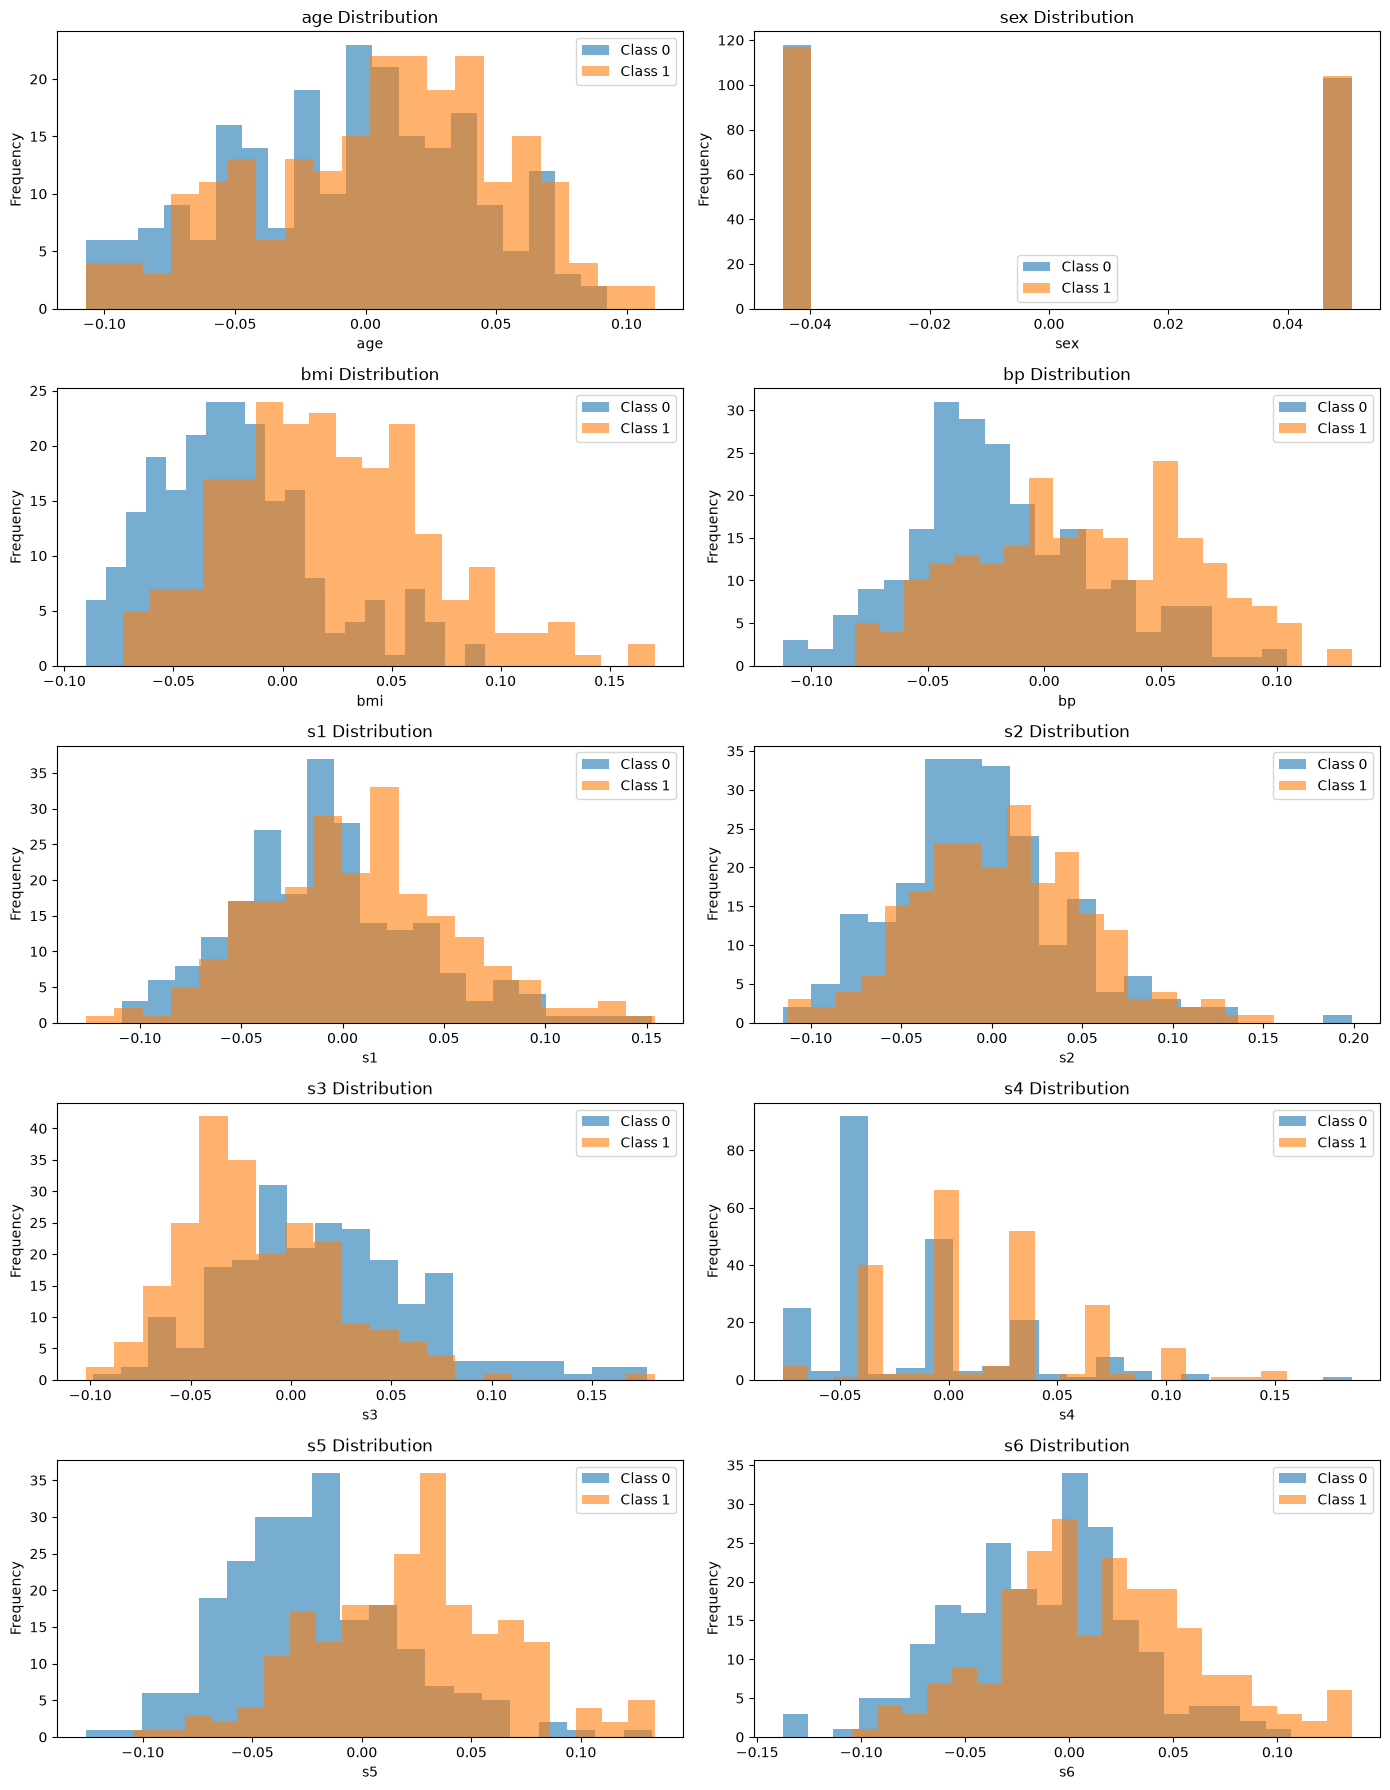

In [5]:
# Histograms for all features
fig, axes = plt.subplots(5, 2, figsize=(14, 18))

for i, feature in enumerate(feature_names):

    ax = axes[i // 2, i % 2]

    ax.hist(
        df[df["class"] == 0][feature],
        bins=20,
        alpha=0.6,
        label="Class 0"
    )

    ax.hist(
        df[df["class"] == 1][feature],
        bins=20,
        alpha=0.6,
        label="Class 1"
    )

    ax.set_title(f"{feature} Distribution")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()

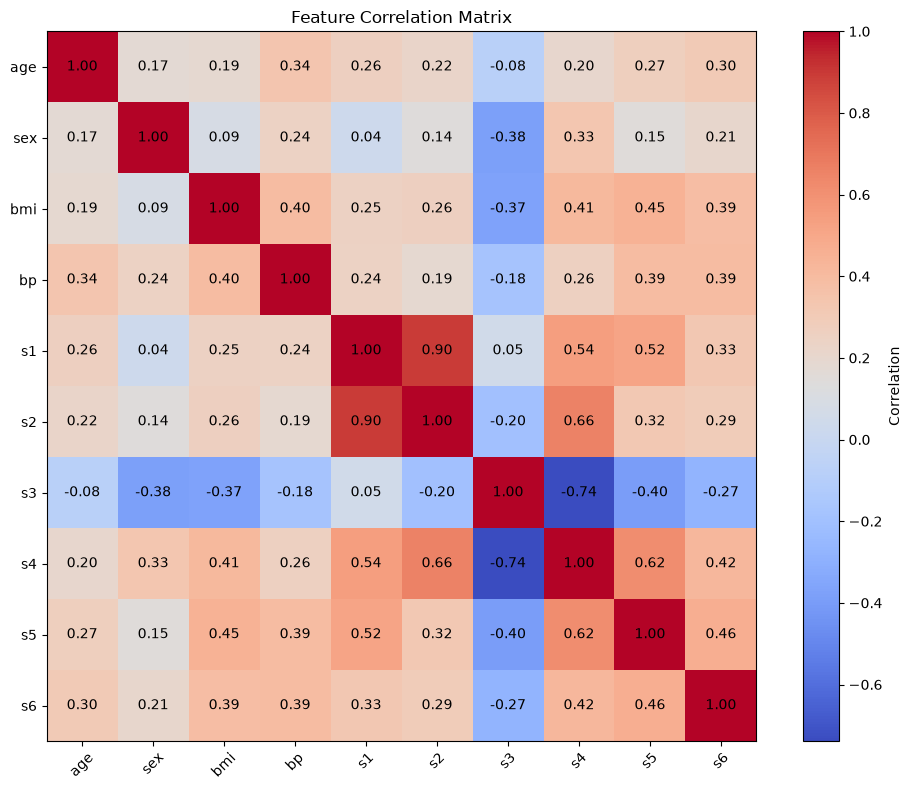

In [6]:
# Correlation matrix
correlation_matrix = df[feature_names].corr()

plt.figure(figsize=(10, 8))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    interpolation="nearest"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(feature_names)),
    feature_names,
    rotation=45
)

plt.yticks(
    range(len(feature_names)),
    feature_names
)

plt.title("Feature Correlation Matrix")

# Display correlation values
for i in range(len(feature_names)):
    for j in range(len(feature_names)):
        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

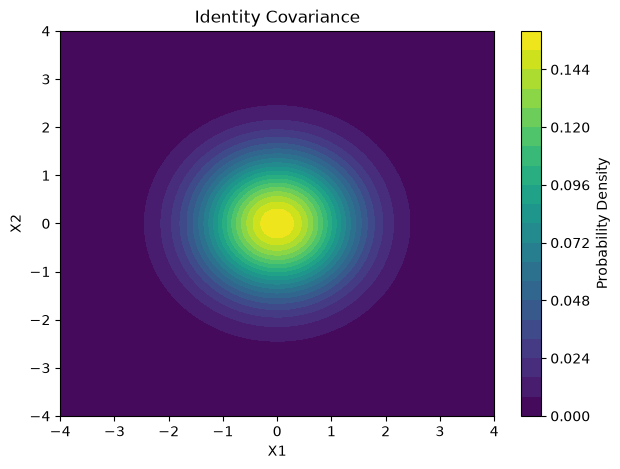

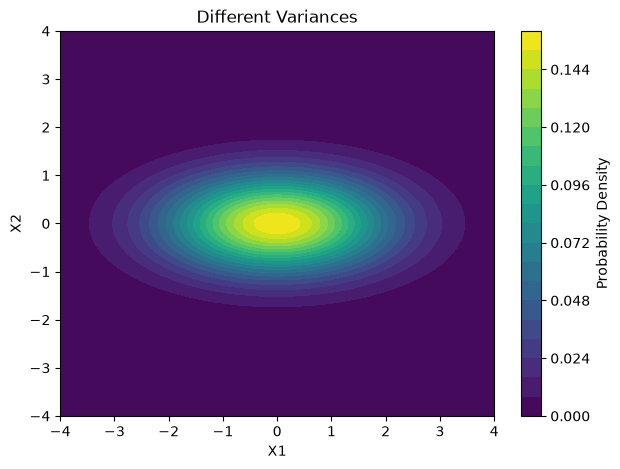

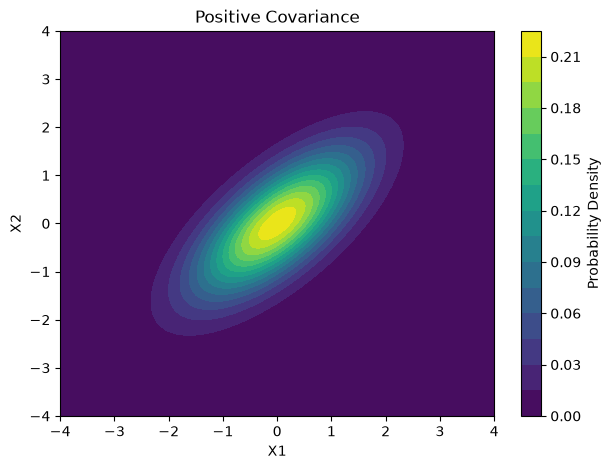

In [7]:
def multivariate_gaussian_pdf(x, mean, covariance):

    x = np.asarray(x)
    mean = np.asarray(mean)

    d = len(mean)

    determinant = np.linalg.det(covariance)
    inverse = np.linalg.inv(covariance)

    difference = x - mean

    exponent = -0.5 * (
        difference.T @ inverse @ difference
    )

    coefficient = 1 / (
        np.sqrt((2 * np.pi) ** d * determinant)
    )

    return coefficient * np.exp(exponent)


# Different covariance matrices
covariances = [
    np.array([
        [1, 0],
        [0, 1]
    ]),

    np.array([
        [2, 0],
        [0, 0.5]
    ]),

    np.array([
        [1, 0.7],
        [0.7, 1]
    ])
]

titles = [
    "Identity Covariance",
    "Different Variances",
    "Positive Covariance"
]


# Create 2D grid
x1 = np.linspace(-4, 4, 100)
x2 = np.linspace(-4, 4, 100)

X1, X2 = np.meshgrid(x1, x2)

mean = np.array([0, 0])


for covariance, title in zip(covariances, titles):

    Z = np.zeros_like(X1)

    for i in range(X1.shape[0]):
        for j in range(X1.shape[1]):

            point = np.array([
                X1[i, j],
                X2[i, j]
            ])

            Z[i, j] = multivariate_gaussian_pdf(
                point,
                mean,
                covariance
            )

    plt.figure(figsize=(7, 5))

    plt.contourf(
        X1,
        X2,
        Z,
        levels=20
    )

    plt.colorbar(label="Probability Density")

    plt.xlabel("X1")
    plt.ylabel("X2")

    plt.title(title)

    plt.show()

In [8]:
class LDAScratch:

    def fit(self, X, y):

        self.classes = np.unique(y)

        # Separate classes
        X0 = X[y == 0]
        X1 = X[y == 1]

        # Class means
        self.mean0 = np.mean(X0, axis=0)
        self.mean1 = np.mean(X1, axis=0)

        # Class covariance matrices
        self.cov0 = np.cov(X0, rowvar=False)
        self.cov1 = np.cov(X1, rowvar=False)

        # Pooled covariance for LDA
        n0 = len(X0)
        n1 = len(X1)

        self.covariance = (
            ((n0 - 1) * self.cov0 +
             (n1 - 1) * self.cov1)
            / (n0 + n1 - 2)
        )

        self.inv_cov = np.linalg.pinv(
            self.covariance
        )

        # Class priors
        self.prior0 = n0 / len(X)
        self.prior1 = n1 / len(X)

        return self


    def discriminant(self, X, mean, prior):

        return (
            X @ self.inv_cov @ mean
            - 0.5 * mean @ self.inv_cov @ mean
            + np.log(prior)
        )


    def predict_proba(self, X):

        d0 = self.discriminant(
            X,
            self.mean0,
            self.prior0
        )

        d1 = self.discriminant(
            X,
            self.mean1,
            self.prior1
        )

        scores = np.column_stack([d0, d1])

        scores = (
            scores -
            np.max(scores, axis=1, keepdims=True)
        )

        probabilities = np.exp(scores)

        probabilities /= np.sum(
            probabilities,
            axis=1,
            keepdims=True
        )

        return probabilities


    def predict(self, X, threshold=0.5):

        probability = self.predict_proba(X)[:, 1]

        return (
            probability >= threshold
        ).astype(int)


# Train LDA using all features
lda = LDAScratch()
lda.fit(X_train, y_train)

lda_predictions = lda.predict(X_test)

print("LDA Accuracy:",
      accuracy_score(y_test, lda_predictions))

LDA Accuracy: 0.7303370786516854


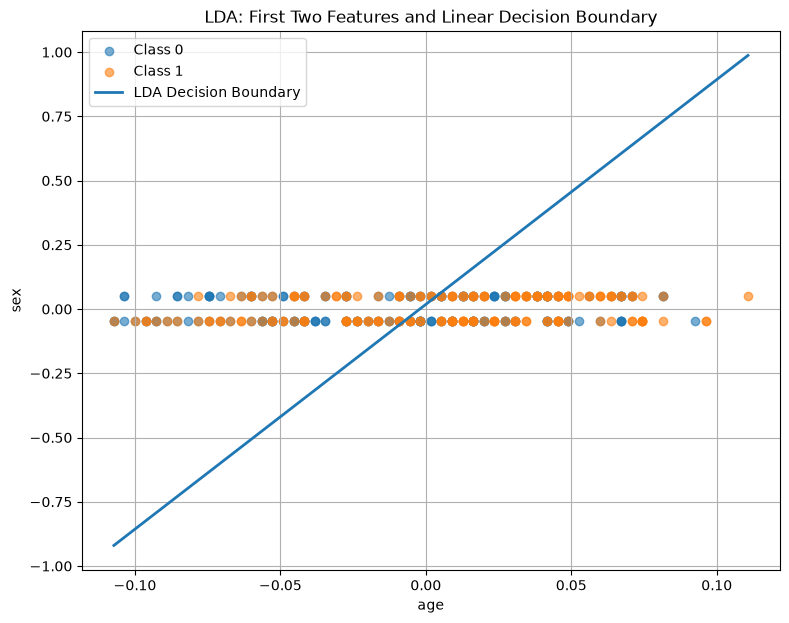

In [9]:
# First two features
X_2d = X_train[:, :2]

lda_2d = LDAScratch()
lda_2d.fit(X_2d, y_train)

# Scatter plot
plt.figure(figsize=(9, 7))

plt.scatter(
    X_2d[y_train == 0, 0],
    X_2d[y_train == 0, 1],
    alpha=0.6,
    label="Class 0"
)

plt.scatter(
    X_2d[y_train == 1, 0],
    X_2d[y_train == 1, 1],
    alpha=0.6,
    label="Class 1"
)

# Linear decision boundary
w = lda_2d.inv_cov @ (
    lda_2d.mean1 - lda_2d.mean0
)

b = (
    -0.5 * lda_2d.mean1 @ lda_2d.inv_cov @ lda_2d.mean1
    + 0.5 * lda_2d.mean0 @ lda_2d.inv_cov @ lda_2d.mean0
    + np.log(
        lda_2d.prior1 /
        lda_2d.prior0
    )
)

x_line = np.linspace(
    X_2d[:, 0].min(),
    X_2d[:, 0].max(),
    100
)

y_line = (
    -(w[0] * x_line + b) / w[1]
)

plt.plot(
    x_line,
    y_line,
    linewidth=2,
    label="LDA Decision Boundary"
)

plt.xlabel(feature_names[0])
plt.ylabel(feature_names[1])

plt.title(
    "LDA: First Two Features and Linear Decision Boundary"
)

plt.legend()
plt.grid()
plt.show()

,Threshold,Accuracy,Precision,Sensitivity,Specificity,F1,FP,FN,Cost
0,0.1,0.617978,0.564103,1.000000,0.244444,0.721311,34,0,3400
1,0.2,0.685393,0.617647,0.954545,0.422222,0.750000,26,2,4600
2,0.3,0.730337,0.678571,0.863636,0.600000,0.760000,18,6,7800
3,0.4,0.730337,0.692308,0.818182,0.644444,0.750000,16,8,9600
4,0.5,0.730337,0.708333,0.772727,0.688889,0.739130,14,10,11400
5,0.6,0.752809,0.775000,0.704545,0.800000,0.738095,9,13,13900
6,0.7,0.719101,0.806452,0.568182,0.866667,0.666667,6,19,19600
7,0.8,0.674157,0.857143,0.409091,0.933333,0.553846,3,26,26300
8,0.9,0.606742,0.909091,0.227273,0.977778,0.363636,1,34,34100



Best Threshold: 0.1
Minimum Cost: 3400.0


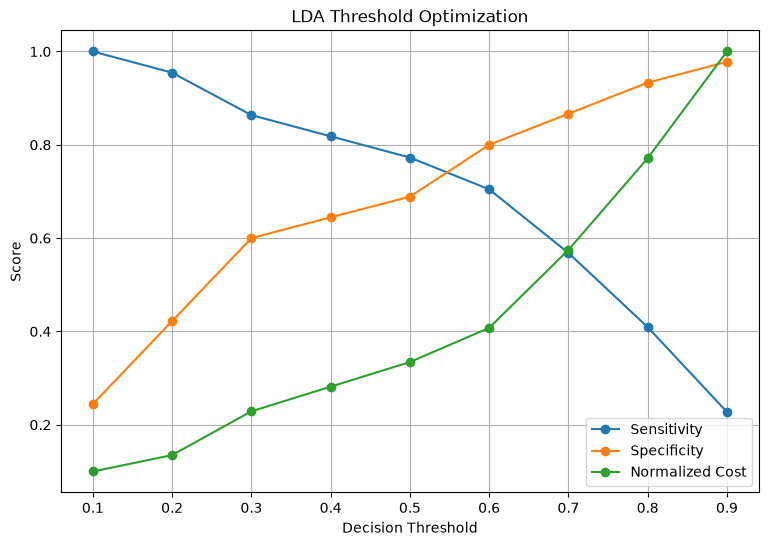

In [10]:
# LDA probability for positive class
lda_probability = lda.predict_proba(X_test)[:, 1]

thresholds = np.arange(
    0.1,
    1.0,
    0.1
)

results = []

# Assume FN is more expensive than FP
FP_COST = 100
FN_COST = 1000


for threshold in thresholds:

    prediction = (
        lda_probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        prediction
    ).ravel()

    accuracy = accuracy_score(
        y_test,
        prediction
    )

    precision = precision_score(
        y_test,
        prediction,
        zero_division=0
    )

    sensitivity = recall_score(
        y_test,
        prediction,
        zero_division=0
    )

    specificity = tn / (tn + fp)

    f1 = f1_score(
        y_test,
        prediction,
        zero_division=0
    )

    cost = (
        fp * FP_COST +
        fn * FN_COST
    )

    results.append([
        threshold,
        accuracy,
        precision,
        sensitivity,
        specificity,
        f1,
        fp,
        fn,
        cost
    ])


results_df = pd.DataFrame(
    results,
    columns=[
        "Threshold",
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1",
        "FP",
        "FN",
        "Cost"
    ]
)

display(results_df)


# Best threshold based on medical cost
best_row = results_df.loc[
    results_df["Cost"].idxmin()
]

print("\nBest Threshold:", best_row["Threshold"])
print("Minimum Cost:", best_row["Cost"])


# Threshold visualization
plt.figure(figsize=(9, 6))

plt.plot(
    results_df["Threshold"],
    results_df["Sensitivity"],
    marker="o",
    label="Sensitivity"
)

plt.plot(
    results_df["Threshold"],
    results_df["Specificity"],
    marker="o",
    label="Specificity"
)

plt.plot(
    results_df["Threshold"],
    results_df["Cost"] / results_df["Cost"].max(),
    marker="o",
    label="Normalized Cost"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("LDA Threshold Optimization")
plt.legend()
plt.grid()
plt.show()

Covariance Matrix - Class 0:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
age,0.002335,0.000283,0.000479,0.000446,0.000749,0.000744,0.000054,0.000355,0.000346,0.000494
sex,0.000283,0.002266,0.000157,0.000516,-0.000076,0.000358,-0.001070,0.000763,0.000043,0.000416
bmi,0.000479,0.000157,0.001432,0.000345,0.000668,0.000834,-0.000619,0.000783,0.000577,0.000564
bp,0.000446,0.000516,0.000345,0.001521,0.000366,0.000413,-0.000195,0.000281,0.000298,0.000642
s1,0.000749,-0.000076,0.000668,0.000366,0.002248,0.002089,0.000235,0.001120,0.001018,0.000530
s2,0.000744,0.000358,0.000834,0.000413,0.002089,0.002383,-0.000575,0.001560,0.000771,0.000567
s3,0.000054,-0.001070,-0.000619,-0.000195,0.000235,-0.000575,0.002481,-0.001495,-0.000571,-0.000373
s4,0.000355,0.000763,0.000783,0.000281,0.001120,0.001560,-0.001495,0.001817,0.000956,0.000503
s5,0.000346,0.000043,0.000577,0.000298,0.001018,0.000771,-0.000571,0.000956,0.001706,0.000595
s6,0.000494,0.000416,0.000564,0.000642,0.000530,0.000567,-0.000373,0.000503,0.000595,0.001917



Covariance Matrix - Class 1:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
age,0.002213,0.000474,0.000151,0.000678,0.000442,0.000269,-0.000126,0.000400,0.000602,0.000594
sex,0.000474,0.002272,0.000249,0.000544,-0.000036,0.000108,-0.000701,0.000612,0.000395,0.000453
bmi,0.000151,0.000249,0.002025,0.000784,0.000310,0.000302,-0.000350,0.000491,0.000469,0.000680
bp,0.000678,0.000544,0.000784,0.002174,0.000550,0.000261,0.000051,0.000256,0.000688,0.000767
s1,0.000442,-0.000036,0.000310,0.000550,0.002194,0.001862,0.000259,0.001072,0.001066,0.000750
s2,0.000269,0.000108,0.000302,0.000261,0.001862,0.002050,-0.000180,0.001249,0.000436,0.000649
s3,-0.000126,-0.000701,-0.000350,0.000051,0.000259,-0.000180,0.001658,-0.001365,-0.000452,-0.000467
s4,0.000400,0.000612,0.000491,0.000256,0.001072,0.001249,-0.001365,0.002163,0.001095,0.000965
s5,0.000602,0.000395,0.000469,0.000688,0.001066,0.000436,-0.000452,0.001095,0.001905,0.000852
s6,0.000594,0.000453,0.000680,0.000767,0.000750,0.000649,-0.000467,0.000965,0.000852,0.002317



Covariance Difference: 0.0027653181017592895


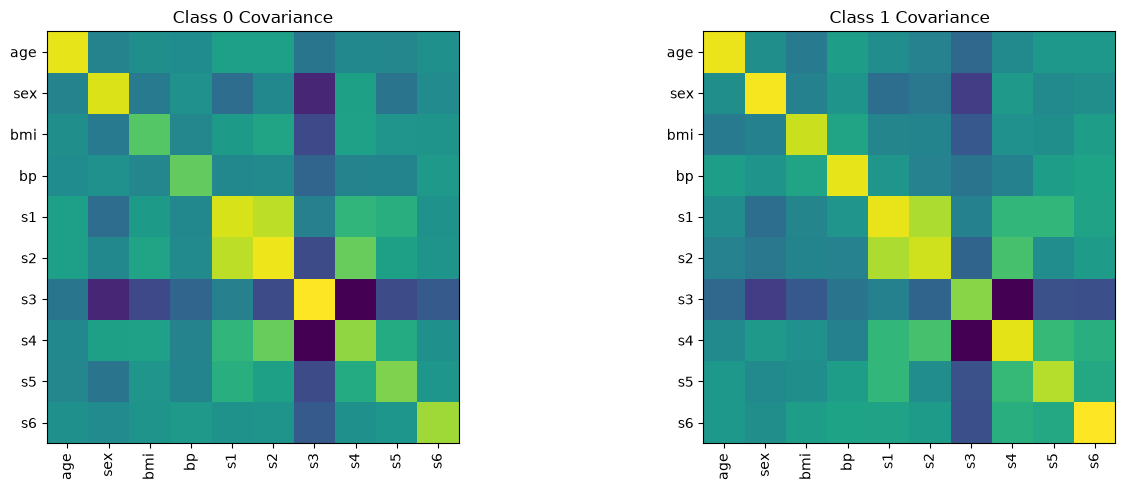

,Metric,LDA,Logistic Regression
0,Accuracy,0.730337,0.775281
1,Precision,0.708333,0.750000
2,Recall,0.772727,0.818182
3,F1 Score,0.739130,0.782609


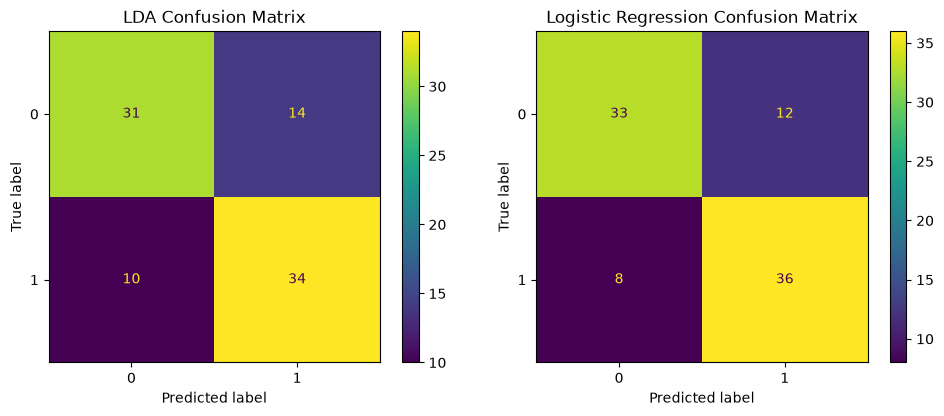

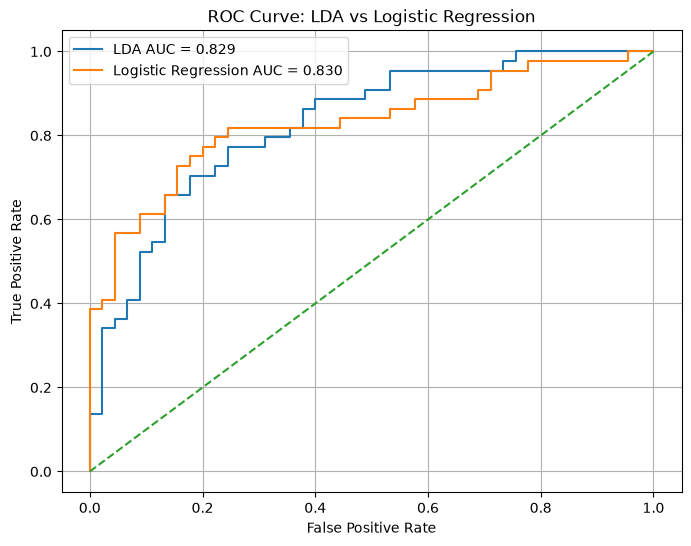

In [11]:
# ==========================================
# 1. Equal Covariance Assumption
# ==========================================

X0 = X_train[y_train == 0]
X1 = X_train[y_train == 1]

cov0 = np.cov(X0, rowvar=False)
cov1 = np.cov(X1, rowvar=False)

# Difference between covariance matrices
covariance_difference = np.linalg.norm(
    cov0 - cov1
)

print("Covariance Matrix - Class 0:")
display(pd.DataFrame(cov0, columns=feature_names,
                     index=feature_names))

print("\nCovariance Matrix - Class 1:")
display(pd.DataFrame(cov1, columns=feature_names,
                     index=feature_names))

print(
    "\nCovariance Difference:",
    covariance_difference
)


# Visual comparison of covariance matrices
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

axes[0].imshow(cov0)
axes[0].set_title("Class 0 Covariance")

axes[1].imshow(cov1)
axes[1].set_title("Class 1 Covariance")

for ax in axes:
    ax.set_xticks(range(len(feature_names)))
    ax.set_yticks(range(len(feature_names)))
    ax.set_xticklabels(feature_names, rotation=90)
    ax.set_yticklabels(feature_names)

plt.tight_layout()
plt.show()


# ==========================================
# 2. Logistic Regression Comparison
# ==========================================

logistic = LogisticRegression(
    max_iter=2000
)

logistic.fit(
    X_train,
    y_train
)

logistic_probability = logistic.predict_proba(
    X_test
)[:, 1]

logistic_prediction = (
    logistic_probability >= 0.5
).astype(int)


# Metrics
lda_accuracy = accuracy_score(
    y_test,
    lda_predictions
)

lda_precision = precision_score(
    y_test,
    lda_predictions,
    zero_division=0
)

lda_recall = recall_score(
    y_test,
    lda_predictions,
    zero_division=0
)

lda_f1 = f1_score(
    y_test,
    lda_predictions,
    zero_division=0
)


log_accuracy = accuracy_score(
    y_test,
    logistic_prediction
)

log_precision = precision_score(
    y_test,
    logistic_prediction,
    zero_division=0
)

log_recall = recall_score(
    y_test,
    logistic_prediction,
    zero_division=0
)

log_f1 = f1_score(
    y_test,
    logistic_prediction,
    zero_division=0
)


comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],

    "LDA": [
        lda_accuracy,
        lda_precision,
        lda_recall,
        lda_f1
    ],

    "Logistic Regression": [
        log_accuracy,
        log_precision,
        log_recall,
        log_f1
    ]
})

display(comparison)


# Confusion matrices
fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4)
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lda_predictions,
    ax=axes[0]
)

axes[0].set_title("LDA Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_prediction,
    ax=axes[1]
)

axes[1].set_title(
    "Logistic Regression Confusion Matrix"
)

plt.tight_layout()
plt.show()


# ROC comparison
lda_fpr, lda_tpr, _ = roc_curve(
    y_test,
    lda_probability
)

log_fpr, log_tpr, _ = roc_curve(
    y_test,
    logistic_probability
)

lda_auc = auc(
    lda_fpr,
    lda_tpr
)

log_auc = auc(
    log_fpr,
    log_tpr
)

plt.figure(figsize=(8, 6))

plt.plot(
    lda_fpr,
    lda_tpr,
    label=f"LDA AUC = {lda_auc:.3f}"
)

plt.plot(
    log_fpr,
    log_tpr,
    label=f"Logistic Regression AUC = {log_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve: LDA vs Logistic Regression")

plt.legend()
plt.grid()
plt.show()